# 🗑️ Klasifikasi Sampah dengan SqueezeNet 1.1 (PyTorch) — split dataset yang sudah ada

Notebook ini mengadaptasi kode `train_245_class.py` (PyTorch) dengan mengganti backbone dari **MobileNetV2** menjadi **SqueezeNet 1.1**, dan menggunakan split dataset yang sudah ada (`waste_squeezenet_data/split`).

**Dataset:** [Recyclable and Household Waste Classification](https://www.kaggle.com/datasets/alistairking/recyclable-and-household-waste-classification) — 15.000 gambar, 30 kategori, 256×256 px.

**Model:** SqueezeNet 1.1 (pretrained ImageNet) — ringan, ~1.2M parameter, cocok untuk CPU.

## 1. Setup & Instalasi

In [1]:
%pip install torch torchvision pillow tqdm scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import shutil
import random
import copy
import time
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix

ImageFile.LOAD_TRUNCATED_IMAGES = True
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print('Device:', device)
print('PyTorch:', torch.__version__)
print('Seed:', SEED)

Device: cuda:0
PyTorch: 2.15.0+cu132
Seed: 42


## 2. Gunakan Split Dataset yang Sudah Ada

In [3]:
WORK_DIR = Path("./waste_squeezenet_data")
SPLIT_DIR = WORK_DIR / "split"

required_splits = ("train", "val", "test")
missing_splits = [
    split_name
    for split_name in required_splits
    if not (SPLIT_DIR / split_name).is_dir()
]
if missing_splits:
    raise FileNotFoundError(
        f"Split dataset tidak ditemukan di {SPLIT_DIR}. "
        f"Folder yang hilang: {missing_splits}. "
        "Pastikan notebook dijalankan dari folder proyek yang berisi "
        "'waste_squeezenet_data/split'."
    )

print("Menggunakan split dataset yang sudah ada:", SPLIT_DIR)

Menggunakan split dataset yang sudah ada: waste_squeezenet_data/split


## 3. Validasi Struktur Split Dataset

In [4]:
valid_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp", ".tif", ".tiff"}

split_classes = {}
for split_name in ("train", "val", "test"):
    split_path = SPLIT_DIR / split_name
    class_dirs = sorted(path.name for path in split_path.iterdir() if path.is_dir())

    if not class_dirs:
        raise RuntimeError(f"Tidak ada folder kelas di {split_path}")

    split_classes[split_name] = set(class_dirs)
    image_count = sum(
        1
        for class_dir in split_path.iterdir()
        if class_dir.is_dir()
        for image_file in class_dir.iterdir()
        if image_file.is_file() and image_file.suffix.lower() in valid_extensions
    )
    print(f"{split_name:5s}: {image_count} images, {len(class_dirs)} classes")

train_classes = split_classes["train"]
for split_name in ("val", "test"):
    if split_classes[split_name] != train_classes:
        raise ValueError(
            f"Daftar kelas pada {split_name} tidak cocok dengan train. "
            "Pastikan struktur folder split sudah lengkap."
        )

print("Struktur split train/val/test valid; dataset tidak disalin atau di-split ulang.")

train: 12000 images, 30 classes
val  : 1500 images, 30 classes
test : 1500 images, 30 classes
Struktur split train/val/test valid; dataset tidak disalin atau di-split ulang.


In [5]:
for phase in ['train', 'val', 'test']:
    n = sum(len(fs) for _, _, fs in os.walk(SPLIT_DIR / phase))
    print(f'{phase:5s}: {n} images')

train: 12000 images
val  : 1500 images
test : 1500 images


## 4. DataLoader (adaptasi `data_load()` dari `train_245_class.py`)

Transformasi sama seperti kode asli (RandomResizedCrop + HorizontalFlip + Normalize ImageNet).

In [6]:
def data_load(data_dir=str(SPLIT_DIR), batch_size=32):
    data_transforms = {
        'train': transforms.Compose([
            transforms.RandomResizedCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
        'val': transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
    }
    data_transforms['test'] = data_transforms['val']

    image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                      for x in ['train', 'val', 'test']}
    dataloaders = {x: DataLoader(image_datasets[x], batch_size=batch_size,
                                  shuffle=(x=='train'), num_workers=2, pin_memory=True)
                   for x in ['train', 'val', 'test']}
    dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}
    class_names = image_datasets['train'].classes
    return dataloaders, dataset_sizes, class_names

dataloaders, dataset_sizes, class_names = data_load(batch_size=32)
print('Jumlah kelas:', len(class_names))
print('Train size :', dataset_sizes['train'])
print('Val size   :', dataset_sizes['val'])
print('Test size  :', dataset_sizes['test'])

Jumlah kelas: 30
Train size : 12000
Val size   : 1500
Test size  : 1500


## 5. Bangun Model SqueezeNet 1.1 (adaptasi `train_main()` dari `train_245_class.py`)

Kita pakai `models.squeezenet1_1(weights='IMAGENET1K_V1')`. Classifier SqueezeNet berbentuk `Sequential(Dropout, Conv2d, ReLU, AdaptiveAvgPool2d)`. Untuk mengganti jumlah output, kita ganti `classifier[1]` (Conv2d) menjadi `nn.Conv2d(512, num_classes, kernel_size=1)`.

In [7]:
def build_squeezenet(num_classes: int, pretrained: bool = True) -> nn.Module:
    weights = models.SqueezeNet1_1_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.squeezenet1_1(weights=weights)
    # Ganti final conv di classifier (index 1) agar output = num_classes
    in_channels = model.classifier[1].in_channels
    model.classifier[1] = nn.Conv2d(in_channels, num_classes, kernel_size=1)
    model.num_classes = num_classes
    # Re-init final conv (mengikuti pola kode asli SqueezeNet)
    nn.init.normal_(model.classifier[1].weight, mean=0.0, std=0.01)
    nn.init.constant_(model.classifier[1].bias, 0)
    return model

model = build_squeezenet(num_classes=len(class_names), pretrained=True).to(device)
print(model.classifier)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable params: {n_params:,}')

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Conv2d(512, 30, kernel_size=(1, 1), stride=(1, 1))
  (2): ReLU(inplace=True)
  (3): AdaptiveAvgPool2d(output_size=(1, 1))
)
Trainable params: 737,886


## 6. Training Loop dan Eksperimen Learning Rate/Scheduler

In [9]:
def train_model(model, dataloaders, dataset_sizes, criterion, optimizer, scheduler, num_epochs=20):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [], 'lr': []
    }

    for epoch in range(num_epochs):
        current_lr = optimizer.param_groups[0]['lr']
        history['lr'].append(current_lr)
        print(f'Epoch {epoch+1}/{num_epochs} | LR: {current_lr:.2e}')
        print('-' * 36)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            with tqdm(total=dataset_sizes[phase], desc=phase) as pbar:
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device, non_blocking=True)
                    labels = labels.to(device, non_blocking=True)

                    optimizer.zero_grad()

                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                    pbar.update(inputs.size(0))

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = (running_corrects.double() / dataset_sizes[phase]).item()
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        # ReduceLROnPlateau needs the validation loss; other schedulers step once per epoch.
        if isinstance(scheduler, lr_scheduler.ReduceLROnPlateau):
            scheduler.step(history['val_loss'][-1])
        elif scheduler is not None:
            scheduler.step()

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:.4f}')

    model.load_state_dict(best_model_wts)
    return model, history

### Catatan dari run awal 2.0

- Akurasi validasi terbaik: **82,13% pada epoch 14**.
- Loss validasi terendah: **0,5979 pada epoch 16**; pada epoch 20 nilainya **0,6033**.
- Pada epoch 20, akurasi train **83,60%** dan validasi **81,53%** (gap **2,07 poin persentase**).
- Ini lebih menunjukkan plateau dengan **sinyal overfitting ringan di akhir**, bukan overfitting berat. Loss validasi hanya naik sedikit setelah titik terendah.

Versi ini memakai split yang sudah ada di `./waste_squeezenet_data/split`: dataset tidak diunduh ulang, disalin/flatten, atau di-split ulang. Tiga konfigurasi memakai **20 epoch**, seed yang sama, dan split yang sama. Konfigurasi dipilih dari metrik validasi; test set baru dievaluasi setelah pemilihan.

In [12]:
NUM_EPOCHS = 20  # tetap sama dengan run awal; belum menambah epoch
MODEL_PATH = 'squeezenet1_1_waste_lr_scheduler.pth'

# Semua eksperimen memakai split, seed, batch size, optimizer SGD, dan jumlah epoch yang sama.
# Tiap model dimulai dari pretrained weights dan inisialisasi classifier yang identik.
EXPERIMENTS = [
    {
        'name': 'baseline_SGD_StepLR_lr1e-3',
        'lr': 1e-3,
        'scheduler': 'step',
    },
    {
        'name': 'SGD_StepLR_lr5e-4',
        'lr': 5e-4,
        'scheduler': 'step',
    },
    {
        'name': 'SGD_ReduceLROnPlateau_lr1e-3',
        'lr': 1e-3,
        'scheduler': 'plateau',
    },
]

criterion = nn.CrossEntropyLoss()
experiment_results = {}

for config in EXPERIMENTS:
    print(f"\n=== {config['name']} ===")
    seed_everything(SEED)
    model_run = build_squeezenet(
        num_classes=len(class_names),
        pretrained=True
    ).to(device)
    optimizer_run = optim.SGD(
        model_run.parameters(),
        lr=config['lr'],
        momentum=0.9
    )

    if config['scheduler'] == 'step':
        scheduler_run = lr_scheduler.StepLR(
            optimizer_run,
            step_size=7,
            gamma=0.1
        )
    else:
        scheduler_run = lr_scheduler.ReduceLROnPlateau(
            optimizer_run,
            mode='min',
            factor=0.5,
            patience=2,
            threshold=1e-3,
            min_lr=1e-5
        )

    trained_model, run_history = train_model(
        model_run,
        dataloaders,
        dataset_sizes,
        criterion,
        optimizer_run,
        scheduler_run,
        num_epochs=NUM_EPOCHS
    )

    experiment_results[config['name']] = {
        'config': config,
        'model': trained_model,
        'history': run_history,
    }

# Pilih checkpoint dengan akurasi validasi terbaik; test set tetap dipakai hanya
# setelah konfigurasi dipilih.
best_name = max(
    experiment_results,
    key=lambda name: max(experiment_results[name]['history']['val_acc'])
)
model = experiment_results[best_name]['model']
history = experiment_results[best_name]['history']
best_val_acc = max(history['val_acc'])
best_val_epoch = int(np.argmax(history['val_acc'])) + 1

torch.save(model, MODEL_PATH)
print(f"\nKonfigurasi terpilih: {best_name}")
print(f"Best validation accuracy: {best_val_acc:.4f} (epoch {best_val_epoch})")
print('Model disimpan ke', MODEL_PATH)

# Ringkasan untuk melihat generalization gap dan tanda overfitting di akhir run.
for name, result in experiment_results.items():
    h = result['history']
    best_loss_idx = int(np.argmin(h['val_loss']))
    min_val_loss = h['val_loss'][best_loss_idx]
    val_loss_delta = h['val_loss'][-1] - min_val_loss
    train_loss_delta = h['train_loss'][-1] - h['train_loss'][best_loss_idx]
    final_acc_gap_pp = 100 * (h['train_acc'][-1] - h['val_acc'][-1])

    late_epochs_above_min = 0
    for value in reversed(h['val_loss']):
        if value > min_val_loss:
            late_epochs_above_min += 1
        else:
            break

    if val_loss_delta > 0 and train_loss_delta < 0 and late_epochs_above_min >= 3:
        signal = 'sinyal ringan: train loss turun, val loss tertahan/naik'
    else:
        signal = 'belum tampak divergensi loss yang konsisten'

    print(
        f"{name}: best val acc={max(h['val_acc']):.4f} "
        f"(epoch {int(np.argmax(h['val_acc'])) + 1}); "
        f"best val loss={min_val_loss:.4f} "
        f"(epoch {best_loss_idx + 1}); "
        f"gap akurasi train-val akhir={final_acc_gap_pp:.2f} pp; "
        f"delta val loss dari minimum={val_loss_delta:+.4f}; "
        f"delta train loss dari epoch minimum val loss={train_loss_delta:+.4f}; "
        f"{signal}"
    )


=== baseline_SGD_StepLR_lr1e-3 ===
Epoch 1/20 | LR: 1.00e-03
------------------------------------


train:   0%|          | 0/12000 [00:00<?, ?it/s]

train: 100%|██████████| 12000/12000 [00:17<00:00, 666.92it/s]


train Loss: 1.5767 Acc: 0.5407


val: 100%|██████████| 1500/1500 [00:01<00:00, 782.23it/s]


val Loss: 1.0671 Acc: 0.6660

Epoch 2/20 | LR: 1.00e-03
------------------------------------


... (232 outputs left out)

train: 100%|██████████| 12000/12000 [00:20<00:00, 599.61it/s]


train Loss: 0.4316 Acc: 0.8594


val: 100%|██████████| 1500/1500 [00:02<00:00, 706.24it/s]

val Loss: 0.6001 Acc: 0.8407

Training complete in 7m 10s
Best val Acc: 0.8407

Konfigurasi terpilih: SGD_ReduceLROnPlateau_lr1e-3
Best validation accuracy: 0.8407 (epoch 20)
Model disimpan ke squeezenet1_1_waste_lr_scheduler.pth
baseline_SGD_StepLR_lr1e-3: best val acc=0.8220 (epoch 16); best val loss=0.5947 (epoch 14); gap akurasi train-val akhir=2.09 pp; delta val loss dari minimum=+0.0115; delta train loss dari epoch minimum val loss=-0.0295; sinyal ringan: train loss turun, val loss tertahan/naik
SGD_StepLR_lr5e-4: best val acc=0.8173 (epoch 17); best val loss=0.6113 (epoch 18); gap akurasi train-val akhir=1.62 pp; delta val loss dari minimum=+0.0053; delta train loss dari epoch minimum val loss=-0.0169; belum tampak divergensi loss yang konsisten
SGD_ReduceLROnPlateau_lr1e-3: best val acc=0.8407 (epoch 20); best val loss=0.6001 (epoch 20); gap akurasi train-val akhir=1.87 pp; delta val loss dari minimum=+0.0000; delta train loss dari epoch minimum val loss=+0.0000; belum tampak d

## 7. Perbandingan Kurva dan Diagnosis Overfitting

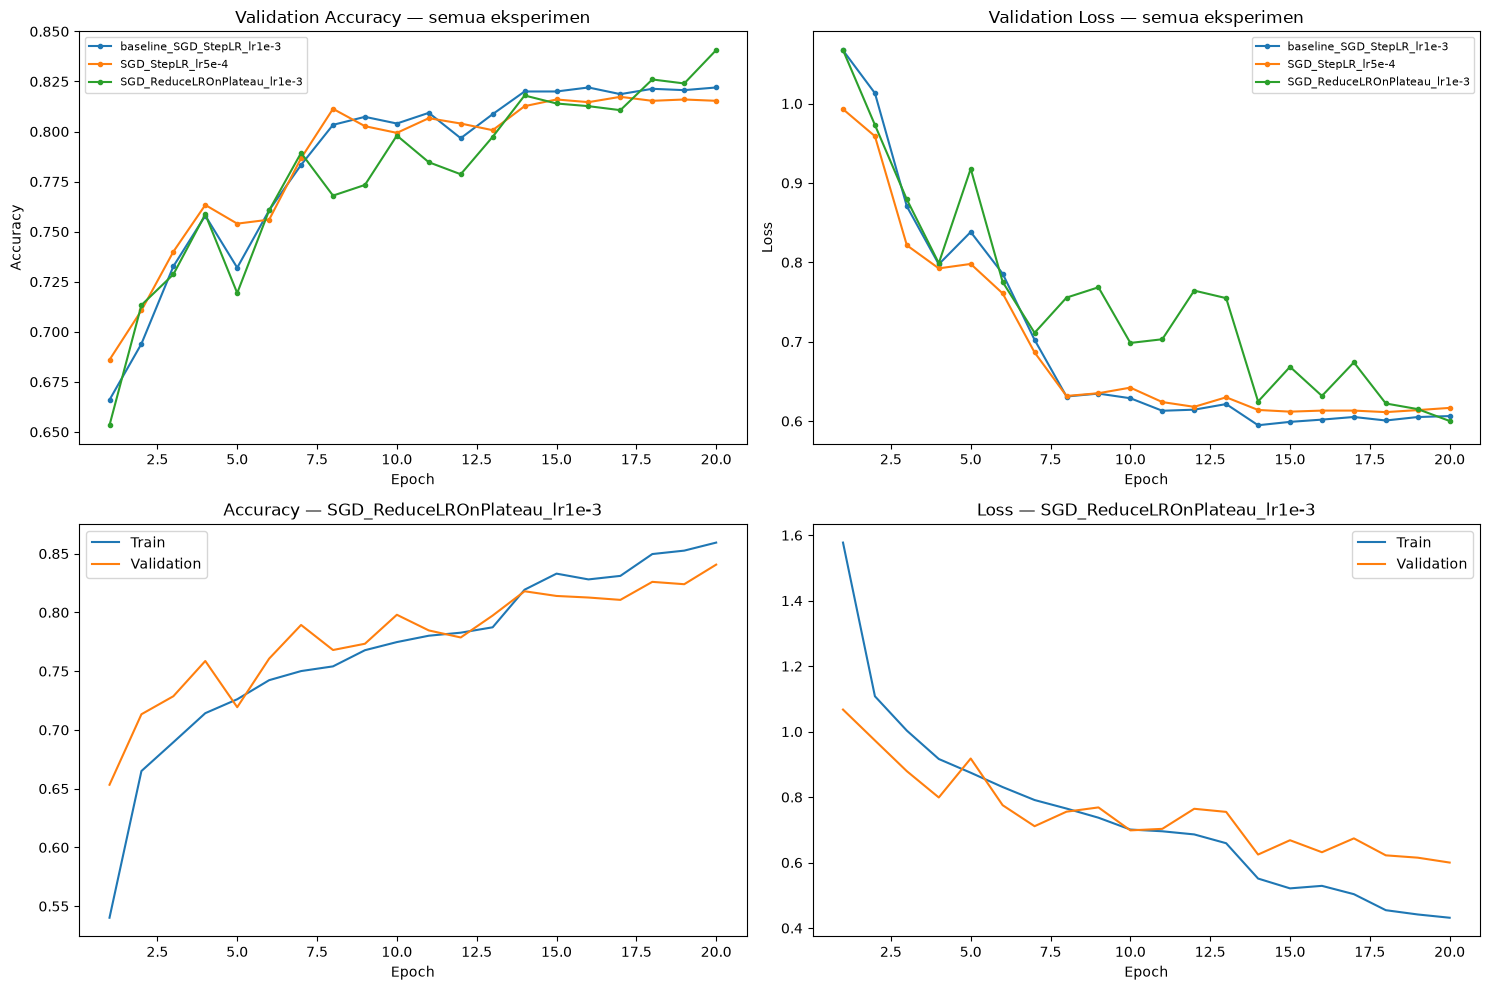

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
epochs = range(1, NUM_EPOCHS + 1)

# Bandingkan metrik validasi untuk semua konfigurasi.
for name, result in experiment_results.items():
    h = result['history']
    axes[0, 0].plot(epochs, h['val_acc'], marker='o', markersize=3, label=name)
    axes[0, 1].plot(epochs, h['val_loss'], marker='o', markersize=3, label=name)

axes[0, 0].set_title('Validation Accuracy — semua eksperimen')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend(fontsize=8)

axes[0, 1].set_title('Validation Loss — semua eksperimen')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend(fontsize=8)

# Kurva train vs validation untuk konfigurasi dengan validation accuracy terbaik.
best_history = experiment_results[best_name]['history']
axes[1, 0].plot(epochs, best_history['train_acc'], label='Train')
axes[1, 0].plot(epochs, best_history['val_acc'], label='Validation')
axes[1, 0].set_title(f'Accuracy — {best_name}')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].legend()

axes[1, 1].plot(epochs, best_history['train_loss'], label='Train')
axes[1, 1].plot(epochs, best_history['val_loss'], label='Validation')
axes[1, 1].set_title(f'Loss — {best_name}')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('results_squeezenet_lr_scheduler.png', dpi=120)
plt.show()

## 8. Evaluasi pada Test Set + Confusion Matrix (adaptasi `zhibiao()` dari `test_model.py`)

In [14]:
def evaluate(model, loader, class_names, device):
    model.eval()
    real, pred = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc='eval'):
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            _, p = torch.max(outputs, 1)
            pred.extend(p.cpu().numpy().tolist())
            real.extend(labels.numpy().tolist())
    return real, pred

test_loader = dataloaders['test']
y_true, y_pred = evaluate(model, test_loader, class_names, device)

acc = np.mean(np.array(y_true) == np.array(y_pred))
print(f'Test accuracy: {acc*100:.2f}%')
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

eval: 100%|██████████| 47/47 [00:02<00:00, 18.61it/s]


Test accuracy: 85.07%
                            precision    recall  f1-score   support

              aerosol_cans       0.92      0.88      0.90        50
        aluminum_food_cans       0.50      0.28      0.36        50
        aluminum_soda_cans       0.83      0.88      0.85        50
           cardboard_boxes       0.70      0.70      0.70        50
       cardboard_packaging       0.72      0.68      0.70        50
                  clothing       0.98      0.84      0.90        50
            coffee_grounds       1.00      0.94      0.97        50
disposable_plastic_cutlery       0.91      0.98      0.94        50
                 eggshells       0.98      0.98      0.98        50
                food_waste       0.96      0.92      0.94        50
    glass_beverage_bottles       0.88      0.86      0.87        50
 glass_cosmetic_containers       0.94      0.96      0.95        50
           glass_food_jars       0.92      0.88      0.90        50
                 magazine

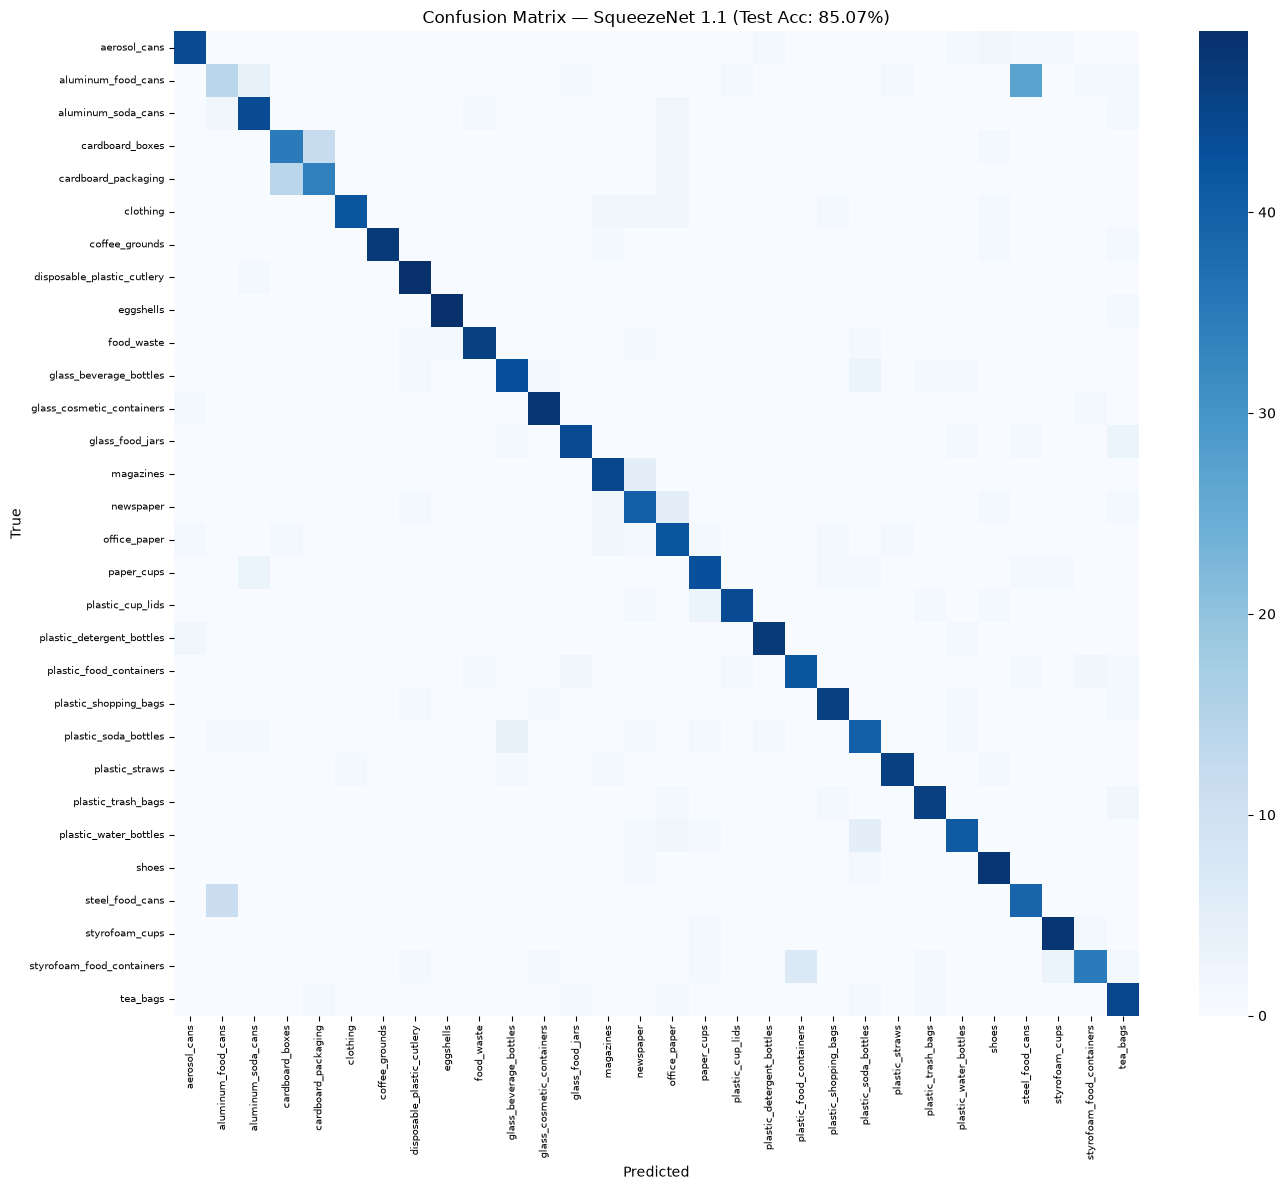

In [15]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix — SqueezeNet 1.1 (Test Acc: {acc*100:.2f}%)')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

## 9. Prediksi Single Image (adaptasi `single_img_predict()` dari `test4singleimg.py`)

File       : waste_squeezenet_data/split/test/eggshells/real_world_Image_37.png
True       : eggshells
Predicted  : eggshells  (conf=1.000)


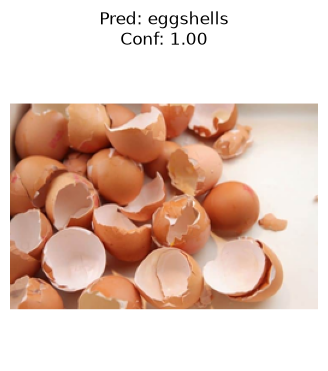

In [55]:
def predict_single(img_path, model, class_names, device=device):
    model.eval()
    tfm = transforms.Compose([
        transforms.Resize([224, 224]),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    img = Image.open(img_path).convert('RGB')
    x = tfm(img).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(x)
        probs = torch.softmax(out, dim=1)
        conf, idx = torch.max(probs, 1)
    return class_names[idx.item()], conf.item()

# Uji dengan sampel dari test set
test_ds = datasets.ImageFolder(str(SPLIT_DIR / 'test'))
sample_idx = random.randint(0, len(test_ds) - 1)
sample_path, true_idx = test_ds.samples[sample_idx]
pred_class, conf = predict_single(sample_path, model, class_names)
true_class = class_names[true_idx]

print(f'File       : {sample_path}')
print(f'True       : {true_class}')
print(f'Predicted  : {pred_class}  (conf={conf:.3f})')

plt.figure(figsize=(4, 4))
plt.imshow(Image.open(sample_path))
plt.title(f'Pred: {pred_class}\nConf: {conf:.2f}')
plt.axis('off')
plt.show()

## 10. (Opsional) Upload Gambar Sendiri

In [ ]:
# from google.colab import files
# uploaded = files.upload()
# for fname in uploaded:
#     pred_class, conf = predict_single(fname, model, class_names)
#     print(f'{fname} -> {pred_class} ({conf:.3f})')
#     plt.imshow(Image.open(fname)); plt.title(pred_class); plt.axis('off'); plt.show()

## 11. Simpan & Unduh Model

In [ ]:
print('Model:', MODEL_PATH, '—', os.path.getsize(MODEL_PATH) / 1e6, 'MB')
# Di Colab:
# from google.colab import files
# files.download(MODEL_PATH)